<a href="https://colab.research.google.com/github/chenorensh1001/CannonSat/blob/main/ENGIMA_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 0: Setup and Configurations
In this step, we install/import the required libraries, mount Google Drive, and configure all global variables and settings.

In [2]:
import os
import glob
import numpy as np
import pandas as pd
import xarray as xr
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from google.colab import drive

# Mount Google Drive securely
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


### Global Settings
This cell contains all configurable paths, parameters, thresholds, and execution flags used throughout the notebook.

In [3]:
# =============================================================================
# GLOBAL SETTINGS
# =============================================================================
ROOT = "/content/drive/MyDrive/University/ENIGMA"

# Execution flags
FORCE_REREAD = False
HIDE_SOFT_FLAGGED = False

# Thresholds
MIN_COAST_DIST_M = 20000  # Minimum distance to coast in meters
MAX_GAP_S = 3            # Maximum gap in seconds for interpolation
MAX_DIST_KM = 5          # Maximum distance tolerance in km for matching
ANOM_K = 4               # Standard deviation threshold factor for anomalies

# Verification check
print("Setup completed.")
print(f"ROOT path configured as: {ROOT}")
print(f"Minimum Coast Distance Threshold: {MIN_COAST_DIST_M} m")
print(f"Anomaly multiplier (K): {ANOM_K}")


Setup completed.
ROOT path configured as: /content/drive/MyDrive/University/ENIGMA
Minimum Coast Distance Threshold: 20000 m
Anomaly multiplier (K): 4


## Step 1: Detect Directory Structure and List Files
This step scans the subfolders within `ROOT` to build a registry of available Sentinel NetCDF datasets, mapping their periods and products case-insensitively, and counting the file inventory.

In [4]:
import re
from collections import defaultdict

def detect_and_register_files(root_path):
    # Registry to store: file_registry[satellite][period][product] = [file_paths...]
    file_registry = defaultdict(lambda: defaultdict(lambda: defaultdict(list)))

    # Walk the directory tree
    for root_dir, dirs, files in os.walk(root_path):
        nc_files = [f for f in files if f.endswith('.nc')]
        if not nc_files:
            continue

        # Standardize path parts relative to ROOT
        rel_parts = os.path.relpath(root_dir, root_path).split(os.sep)

        # Identify Satellite
        sat_match = None
        for part in rel_parts:
            part_upper = part.upper()
            if "SENTINEL 3A" in part_upper or "SENTINEL-3A" in part_upper or "S3A" in part_upper:
                sat_match = "S3A"
                break
            elif "SENTINEL 3B" in part_upper or "SENTINEL-3B" in part_upper or "S3B" in part_upper:
                sat_match = "S3B"
                break
            elif "SENTINEL 6" in part_upper or "SENTINEL-6" in part_upper or "S6" in part_upper:
                sat_match = "S6"
                break

        if not sat_match:
            continue  # Skip directories not belonging to these satellites

        # Identify Period (Baseline, Storm) and Product (NRT, NTC)
        period_label = None
        product_label = None

        for part in rel_parts:
            part_lower = part.lower()
            if "storm" in part_lower:
                period_label = "storm"
            elif "baseline" in part_lower:
                # Treat each baseline folder name as its unique label
                period_label = f"baseline_{part_lower}"

            if "nrt" in part_lower:
                product_label = "NRT"
            elif "ntc" in part_lower:
                product_label = "NTC"

        # Default fallback assignments if directories are direct
        if not period_label:
            continue
        if not product_label:
            continue

        # Add found files to our registry
        for file_name in nc_files:
            full_path = os.path.join(root_dir, file_name)
            file_registry[sat_match][period_label][product_label].append(full_path)

    return file_registry

# Run directory scan
file_registry = detect_and_register_files(ROOT)


### Verification and Summary Check
Now, let's print out the structure of the found satellite files in a clean, readable format to confirm everything matches the expectations.

In [5]:
print("=== DETECTED FILE INVENTORY ===\n")
total_files_found = 0

for sat in sorted(file_registry.keys()):
    print(f"Satellite: {sat}")
    for period in sorted(file_registry[sat].keys()):
        print(f"  Period: {period}")
        for product in sorted(file_registry[sat][period].keys()):
            file_count = len(file_registry[sat][period][product])
            total_files_found += file_count
            print(f"    [{product}] -> {file_count} netCDF (.nc) files")
    print()

print(f"Total unique NetCDF files registered: {total_files_found}")


=== DETECTED FILE INVENTORY ===

Satellite: S3A
  Period: baseline_baseline
    [NRT] -> 452 netCDF (.nc) files
    [NTC] -> 88 netCDF (.nc) files
  Period: storm
    [NRT] -> 485 netCDF (.nc) files
    [NTC] -> 86 netCDF (.nc) files

Satellite: S3B
  Period: baseline_baseline
    [NRT] -> 457 netCDF (.nc) files
    [NTC] -> 88 netCDF (.nc) files
  Period: storm
    [NRT] -> 591 netCDF (.nc) files
    [NTC] -> 86 netCDF (.nc) files

Satellite: S6
  Period: baseline_baseline 18.05.26 - 20.05.26
    [NRT] -> 39 netCDF (.nc) files
    [NTC] -> 79 netCDF (.nc) files
  Period: baseline_baseline 30.12.2025 - 2.1.2026 
    [NRT] -> 40 netCDF (.nc) files
    [NTC] -> 80 netCDF (.nc) files
  Period: storm
    [NRT] -> 39 netCDF (.nc) files
    [NTC] -> 78 netCDF (.nc) files

Total unique NetCDF files registered: 2688


## Step 2: Inspect Sample Files and Confirm Variables
This step opens one sample NetCDF file for Sentinel-3 and one for Sentinel-6. It maps and checks that all required variables from Section B are present, printing their long names, units, scale factors, offsets, and fill values to ensure data integrity before loading.

In [6]:
# Define variables mapping for both Sentinel-3 and Sentinel-6
# key: short_name, value: (Sentinel-3 name, Sentinel-6 path/name)
VARIABLE_MAPS = {
    # Main variables
    'time': ('time_01', 'data_01/time'),
    'lat': ('lat_01', 'data_01/latitude'),
    'lon': ('lon_01', 'data_01/longitude'),
    'ssha': ('ssha_01_ku', 'data_01/ku/ssha'),
    'iono_filt': ('iono_cor_alt_filtered_01_ku', 'data_01/iono_cor_alt_filtered'),
    'alt': ('alt_01', 'data_01/altitude'),
    # Ionosphere, orbit, ssb
    'iono_alt': ('iono_cor_alt_01_ku', 'data_01/iono_cor_alt'),
    'iono_gim': ('iono_cor_gim_01_ku', 'data_01/ku/iono_cor_gim'),
    'tec': ('total_electron_content_01', 'data_01/total_electron_content'),
    'alt_rate': ('orb_alt_rate_01', 'data_01/altitude_rate'),
    'orbit_type': ('orbit_type_01', 'data_01/orbit_type_flag'),
    'range_ku': ('range_ocean_01_ku', 'data_01/ku/range_ocean'),
    'range_c': ('range_ocean_01_c', 'data_01/c/range_ocean'),
    'ssb_ku': ('sea_state_bias_01_ku', 'data_01/ku/sea_state_bias'),
    'ssb_c': ('sea_state_bias_01_c', 'data_01/c/sea_state_bias'),
    'swh': ('swh_ocean_01_ku', 'data_01/ku/swh_ocean'),
    'sig0': ('sig0_ocean_01_ku', 'data_01/ku/sig0_ocean'),
    # Corrections
    'dry_tropo': ('mod_dry_tropo_cor_zero_altitude_01', 'data_01/model_dry_tropo_cor_zero_altitude'),
    'wet_tropo': ('rad_wet_tropo_cor_01_ku', 'data_01/rad_wet_tropo_cor'),
    'wet_model': ('mod_wet_tropo_cor_zero_altitude_01', 'data_01/model_wet_tropo_cor_zero_altitude'),
    'inv_bar': ('inv_bar_cor_01', 'data_01/inv_bar_cor'),
    'ocean_tide': ('ocean_tide_sol2_01', 'data_01/ocean_tide_sol2'),
    'solid_tide': ('solid_earth_tide_01', 'data_01/solid_earth_tide'),
    'pole_tide': ('pole_tide_01', 'data_01/pole_tide'),
    'mss': ('mean_sea_surf_sol1_01', 'data_01/mean_sea_surface_sol1'),
    # Flags
    'surf_class': ('surf_class_01', 'data_01/surface_classification_flag'),
    'dist_coast': ('dist_coast_01', 'data_01/distance_to_coast'),
    'qual_range': ('range_ocean_qual_01_ku', 'data_01/ku/range_ocean_qual'),
    'rain_flag': ('rain_flag_01_ku', 'data_01/rain_flag'),
    'ice_flag': ('open_sea_ice_flag_01_ku', 'data_01/amr_sea_ice_flag'),
    'manoeuvre': ('manoeuvre_flag_01', 'data_01/manoeuvre_flag')
}

def inspect_file(file_path, sat_type):
    print(f"=== INSPECTING {sat_type} SAMPLE ===")
    print(f"File: {os.path.basename(file_path)}\n")

    with xr.open_dataset(file_path) as ds:
        for short_name, mapped_vars in VARIABLE_MAPS.items():
            var_name = mapped_vars[0] if sat_type == 'S3' else mapped_vars[1]

            # For S6, check if it exists in group structures
            exists = False
            var_obj = None

            if sat_type == 'S3':
                if var_name in ds:
                    exists = True
                    var_obj = ds[var_name]
            else:
                # Sentinel-6 Group traversal fallback
                try:
                    # xarray can open groups or flat structures with group arguments.
                    # We also check if we can access via slash notation if loaded flat.
                    if var_name in ds:
                        exists = True
                        var_obj = ds[var_name]
                    else:
                        # Open dataset group manually to inspect
                        parts = var_name.split('/')
                        group_path = "/".join(parts[:-1])
                        target_var = parts[-1]
                        with xr.open_dataset(file_path, group=group_path) as ds_group:
                            if target_var in ds_group:
                                exists = True
                                var_obj = ds_group[target_var]
                except Exception:
                    pass

            if exists and var_obj is not None:
                units = var_obj.attrs.get('units', 'N/A')
                long_name = var_obj.attrs.get('long_name', 'N/A')
                fill_val = var_obj.attrs.get('_FillValue', 'N/A')
                scale = var_obj.attrs.get('scale_factor', 1.0)
                offset = var_obj.attrs.get('add_offset', 0.0)
                print(f"{short_name:<12} -> Found: {var_name:<45} | Units: {units:<10} | Scale: {scale} | Offset: {offset} | FillVal: {fill_val}")
            else:
                print(f"{short_name:<12} -> [MISSING] looked for: {var_name}")
    print("\n")


### Sample Verification Run
Let's run the inspection for S3A and S6 sample files.

In [7]:
# Select one file from S3A and S6 list
s3a_sample = file_registry['S3A']['storm']['NTC'][0]
s6_sample = file_registry['S6']['storm']['NTC'][0]

inspect_file(s3a_sample, 'S3')
inspect_file(s6_sample, 'S6')


=== INSPECTING S3 SAMPLE ===
File: S3A_SR_2_WAT_STD__NT_135_232_20260118T235633_20260119T004101_G62.nc

time         -> Found: time_01                                       | Units: N/A        | Scale: 1.0 | Offset: 0.0 | FillVal: N/A
lat          -> Found: lat_01                                        | Units: degrees_north | Scale: 1.0 | Offset: 0.0 | FillVal: N/A
lon          -> Found: lon_01                                        | Units: degrees_east | Scale: 1.0 | Offset: 0.0 | FillVal: N/A
ssha         -> Found: ssha_01_ku                                    | Units: m          | Scale: 1.0 | Offset: 0.0 | FillVal: N/A
iono_filt    -> Found: iono_cor_alt_filtered_01_ku                   | Units: m          | Scale: 1.0 | Offset: 0.0 | FillVal: N/A
alt          -> Found: alt_01                                        | Units: m          | Scale: 1.0 | Offset: 0.0 | FillVal: N/A
iono_alt     -> Found: iono_cor_alt_01_ku                            | Units: m          | Scale: 1.0 | O

## Step 3: Read and Cache Files as Parquet
This step parses all registered NetCDF files, maps their variable groups, calculates required corrections, extracts cycle/pass global attributes, deduplicates overlaps, and caches the clean tabular data as Parquet files inside `ROOT/cache/`.

### Why These Procedures Are Crucial:

#### 1. Longitude Alignment ($0$ to $360^\circ$ vs $-180$ to $180^\circ$)
* **The Coordinate Problem:** Altimetry NetCDF files store longitude in a standard $0$ to $360^\circ$ range. However, standard geospatial equations (like the **Haversine formula** used in Step 5 for track matching) expect coordinates in the standard $[-180, 180^\circ)$ range.
* **The Boundary Discontinuity Hazard:** If a satellite pass crosses the Prime Meridian or the International Date Line (e.g., transitioning from $359.9^\circ$ to $0.1^\circ$), performing spatial interpolation or distance math without alignment will calculate a massive coordinate leap ($\\approx 360^\circ$ or thousands of kilometers) instead of a tiny true spatial step ($0.2^\circ$). Storing `lon_180` resolves this boundary discontinuity cleanly.

#### 2. Metadata-Derived Cycle & Pass (Instead of Filename Parsing)
* **Filename Fallacy:** In Sentinel-3 Near Real-Time (NRT) datasets, the orbit numbers encoded in the file name strings represent **relative orbit numbers** rather than the actual ground-track **pass numbers**.
* **Matching Failure:** Attempting to match baseline passes with storm passes using numbers parsed from the file name text will map completely different physical passes from separate regions of the globe.
* **The Solution:** The true **cycle_number** and **pass_number** are explicitly defined inside the NetCDF global attributes (metadata headers). Reading them directly from the headers ensures we are matching the exact same physical ground tracks.

#### 3. The 4 Derived Fields Created:
1. **`lon_180` (Aligned Longitude):** Rescales longitudes $> 180^\circ$ to the range $[-180, 180^\circ)$ so that distance and interpolation calculations do not fail near boundary edges.
2. **`dac` (Dynamic Atmospheric Correction for Sentinel-3):** Sentinel-6 includes a precomputed `dac` variable, but Sentinel-3 does not. We manually compile it for Sentinel-3 by summing the inverse barometer effect and high-frequency atmospheric fluctuations: `dac = inv_bar_cor_01 + hf_fluct_cor_01` to enable fair comparisons.
3. **`pass_dir` (Pass Direction Flag):** Tracks must only be matched with other tracks of the same flight direction (ascending vs descending). If the direction flag is missing, we calculate it dynamically based on the monotonic trend of latitude over time within each individual pass file (0 for ascending, 1 for descending).
4. **`ssha_gim` (GIM-corrected SSHA):** Computes SSHA using the global Global Ionosphere Map (GIM) modeling rather than the dual-frequency radar altimeter measurement: `ssha + iono_filt - iono_gim`. This acts as a robust diagnostic fallback during severe geomagnetic storms.

In [8]:
import warnings
import pyarrow as pa
import pyarrow.parquet as pq
from xarray import SerializationWarning
warnings.filterwarnings('ignore', category=SerializationWarning)

CACHE_DIR = os.path.join(ROOT, "cache")
os.makedirs(CACHE_DIR, exist_ok=True)

def parse_nc_file(file_path, sat_type, period, product):
    try:
        # Open dataset EXACTLY ONCE to avoid multiple slow Google Drive I/O calls
        with xr.open_dataset(file_path) as ds:
            cycle = ds.attrs.get('cycle_number', np.nan)
            pass_num = ds.attrs.get('pass_number', ds.attrs.get('pass_num', np.nan))

            extracted_data = {}

            # Process each mapped variable from Step 2
            for short_name, mapped_vars in VARIABLE_MAPS.items():
                var_name = mapped_vars[0] if sat_type in ('S3A', 'S3B') else mapped_vars[1]

                val = None
                # For S3, read directly from root
                if sat_type in ('S3A', 'S3B'):
                    if var_name in ds:
                        val = ds[var_name].values
                # For S6, support slash-separated group paths safely
                else:
                    if '/' in var_name:
                        group_path, target_var = var_name.rsplit('/', 1)
                        try:
                            # Access groups directly if supported, or fall back via xr.open_dataset
                            with xr.open_dataset(file_path, group=group_path) as ds_group:
                                if target_var in ds_group:
                                    val = ds_group[target_var].values
                        except Exception:
                            pass
                    else:
                        if var_name in ds:
                            val = ds[var_name].values

                if val is not None:
                    if hasattr(val, 'filled'):
                        val = val.filled(np.nan)

                    # Do not cast 'time' to float
                    if short_name == 'time':
                        extracted_data[short_name] = pd.Series(val)
                    else:
                        extracted_data[short_name] = pd.Series(val).astype(float)
                else:
                    extracted_data[short_name] = pd.Series(dtype=float)

            df = pd.DataFrame(extracted_data)
            if df.empty or 'time' not in df or df['time'].isna().all():
                return None

            # Add metadata columns
            df['satellite'] = sat_type
            df['period'] = period
            df['product'] = product
            df['cycle'] = int(cycle) if not np.isnan(cycle) else -1
            df['pass'] = int(pass_num) if not np.isnan(pass_num) else -1
            df['source_file'] = os.path.basename(file_path)

            # Convert time safely
            if pd.api.types.is_datetime64_any_dtype(df['time']):
                df['time'] = pd.to_datetime(df['time'])
            else:
                ref_time = pd.Timestamp('2000-01-01 00:00:00', tz='UTC')
                df['time'] = ref_time + pd.to_timedelta(df['time'], unit='s')

            df['time'] = df['time'].dt.tz_localize(None)

            # Longitude scaling: also store as -180 to 180
            if 'lon' in df.columns:
                df['lon_180'] = df['lon'].map(lambda l: l - 360 if l > 180 else l)

            # Sentinel-3 DAC Correction construction: dac = inv_bar_cor_01 + hf_fluct_cor_01
            if sat_type in ('S3A', 'S3B'):
                try:
                    hf_fluct = ds['hf_fluct_cor_01'].values
                    if hasattr(hf_fluct, 'filled'):
                        hf_fluct = hf_fluct.filled(np.nan)
                    df['dac'] = df['inv_bar'] + hf_fluct
                except Exception:
                    df['dac'] = np.nan
                df['geo_sum'] = np.nan
            else:
                pass

            # Calculate pass direction (pass_dir) if missing
            if 'pass_dir' not in df.columns or df['pass_dir'].isna().all():
                if len(df) > 1:
                    lat_diff = df['lat'].iloc[-1] - df['lat'].iloc[0]
                    df['pass_dir'] = 0 if lat_diff > 0 else 1
                else:
                    df['pass_dir'] = np.nan

            return df
    except Exception as e:
        print(f"Warning: Failed to parse file {os.path.basename(file_path)}: {e}")
        return None

def build_and_cache_dataset(sat_type, period, product, paths):
    cache_file = os.path.join(CACHE_DIR, f"{sat_type}_{period}_{product}.parquet")

    if os.path.exists(cache_file) and not FORCE_REREAD:
        print(f"Loading {sat_type} {period} [{product}] from Cache...")
        return pd.read_parquet(cache_file)

    print(f"Processing and caching {len(paths)} NetCDF files for {sat_type} {period} [{product}]...")

    dfs = []
    # Test on first 2 files first to ensure structural robustness
    test_paths = paths[:2] if len(paths) >= 2 else paths
    for path in test_paths:
        df = parse_nc_file(path, sat_type, period, product)
        if df is not None:
            dfs.append(df)

    # Process remaining files
    remaining_paths = paths[2:] if len(paths) >= 2 else []
    for path in tqdm(remaining_paths, desc=f"Loading {sat_type} {product}"):
        df = parse_nc_file(path, sat_type, period, product)
        if df is not None:
            dfs.append(df)

    if not dfs:
        print(f"Warning: No valid data found for {sat_type} {period} [{product}]")
        return pd.DataFrame()

    full_df = pd.concat(dfs, ignore_index=True)

    # Drop duplicate timestamps (keep first)
    full_df = full_df.drop_duplicates(subset=['time']).sort_values('time').reset_index(drop=True)

    # Save to Parquet
    full_df.to_parquet(cache_file, index=False)
    return full_df

### Cache Generation and Verification Run
Let's load or build the un-filtered datasets for all configuration pairs, and print verification statistics for each output.

In [9]:
data_cache = defaultdict(lambda: defaultdict(dict))

# Run the parsing on all combinations of the registered structure
for sat in sorted(file_registry.keys()):
    for period in sorted(file_registry[sat].keys()):
        for product in sorted(file_registry[sat][period].keys()):
            paths = file_registry[sat][period][product]
            df = build_and_cache_dataset(sat, period, product, paths)
            data_cache[sat][period][product] = df

            # Verification outputs
            if not df.empty:
                print(f"  -> Cached Rows: {len(df)}")
                print(f"  -> Time Span:  {df['time'].min()} to {df['time'].max()}")
                print(f"  -> Unique Passes: {df['pass'].nunique()}")
            print("-"*50)


Loading S3A baseline_baseline [NRT] from Cache...
  -> Cached Rows: 183699
  -> Time Span:  2025-12-22 23:11:03 to 2025-12-26 00:33:15
  -> Unique Passes: 88
--------------------------------------------------
Loading S3A baseline_baseline [NTC] from Cache...
  -> Cached Rows: 185596
  -> Time Span:  2025-12-22 22:15:33 to 2025-12-26 00:18:58
  -> Unique Passes: 88
--------------------------------------------------
Loading S3A storm [NRT] from Cache...
  -> Cached Rows: 195162
  -> Time Span:  2026-01-19 00:00:36 to 2026-01-23 00:06:48
  -> Unique Passes: 97
--------------------------------------------------
Loading S3A storm [NTC] from Cache...
  -> Cached Rows: 177704
  -> Time Span:  2026-01-18 23:56:33 to 2026-01-22 00:18:58
  -> Unique Passes: 86
--------------------------------------------------
Loading S3B baseline_baseline [NRT] from Cache...
  -> Cached Rows: 184003
  -> Time Span:  2025-12-22 23:00:11 to 2025-12-26 00:24:48
  -> Unique Passes: 88
------------------------------

## Step 4: Quality Filtering and Flagging Thresholds

In this step, we establish a robust filtering engine to screen out corrupted, degraded, or land-contaminated altimeter records. According to standard physical oceanography requirements, we implement the following filters:

1. **Distance to Coast (`dist_coast`):** Exclude all records closer than $20\text{ km}$ ($20,000\text{ m}$) to the coastline (`dist_coast_01 < MIN_COAST_DIST_M`) to prevent radar waveform contamination from land reflections.
2. **Open Ocean Surface Classification (`surf_class`):** Keep only records explicitly flagged as open ocean (e.g., standard flag value of `0` indicating ocean).
3. **Rain Contamination Check (`rain_flag`):** Heavy rain attenuates Ku-band radar pulses, degrading ranges. We filter out records flagged as raining.
4. **Sea Ice Interference (`ice_flag`):** Any presence of sea ice alters the waveform shape. We retain only records classified as open water/no ice.
5. **Maneuver Exclusions (`manoeuvre`):** Altimetry measurements taken during satellite thruster firings or altitude adjustments have degraded orbit quality and must be excluded.
6. **Range Quality Flag (`qual_range`):** We check the internal instrumentation quality indicators to confirm the validity of the computed radar range.
7. **Physical Bound Checks:** To eliminate absolute outliers, we constrain standard variables within physical limits:
   * Latitude ($"\text{lat}"$) must fall within $[-90^\circ, 90^\circ]$
   * Longitude ($"\text{lon}"$) must fall within $[0^\circ, 360^\circ]$
   * SSHA ($"\text{ssha}"$) must be physically realistic (e.g., within $[-2.0\text{ m}, 2.0\text{ m}]$)

In [10]:
def filter_dataset(df):
    """
    Applies strict physical, geographical, and meteorological quality control filters
    to the loaded dataframe according to scientific altimetry thresholds.
    """
    if df.empty:
        return df

    # Track initial size for statistics reporting
    initial_rows = len(df)

    # 1. Geographical Range checks
    geo_mask = (
        (df['lat'] >= -90.0) & (df['lat'] <= 90.0) &
        (df['lon'] >= 0.0) & (df['lon'] <= 360.0)
    )

    # 2. Distance to Coast filter (20km limit defined in Step 0 settings)
    coast_mask = df['dist_coast'] >= MIN_COAST_DIST_M

    # 3. Instrument and Surface Flags
    # surf_class: 0 = Open Ocean
    surf_mask = df['surf_class'] == 0

    # rain_flag: 0 = No rain
    rain_mask = df['rain_flag'] == 0

    # ice_flag: 0 = No ice
    ice_mask = df['ice_flag'] == 0

    # manoeuvre_flag: 0 = No maneuver
    manoeuvre_mask = df['manoeuvre'] == 0

    # qual_range: 0 = Good range
    qual_mask = df['qual_range'] == 0

    # 4. Outlier SSHA constraints (within +/- 2.0 meters)
    ssha_mask = (df['ssha'] >= -2.0) & (df['ssha'] <= 2.0)

    # Combine all flags into a single Boolean filter array
    clean_mask = (
        geo_mask &
        coast_mask &
        surf_mask &
        rain_mask &
        ice_mask &
        manoeuvre_mask &
        qual_mask &
        ssha_mask
    )

    filtered_df = df[clean_mask].copy().reset_index(drop=True)

    # Print filtration metrics
    accepted_rows = len(filtered_df)
    discarded_rows = initial_rows - accepted_rows
    pct_discarded = (discarded_rows / initial_rows) * 100 if initial_rows > 0 else 0

    print(f"Filtration Complete: Registered {accepted_rows} clean records.")
    print(f"  -> Discarded {discarded_rows} degraded records ({pct_discarded:.2f}% of raw rows).")

    return filtered_df

### Test Filtering on Sample Baseline Data

Let's apply this new filter to one of our cached baseline datasets to verify the output statistics and observe the data reduction.

In [11]:
# Fetch the S3A Baseline NRT dataframe from our memory cache
test_key = ('S3A', 'baseline_baseline', 'NRT')
if test_key[0] in data_cache and test_key[1] in data_cache[test_key[0]] and test_key[2] in data_cache[test_key[0]][test_key[1]]:
    raw_test_df = data_cache[test_key[0]][test_key[1]][test_key[2]]
    print(f"Testing filters on raw dataset size: {len(raw_test_df)} rows...")
    clean_test_df = filter_dataset(raw_test_df)
else:
    print("Cache not fully loaded yet. Please wait for Step 3 to write outputs, then run this verification cell.")

Testing filters on raw dataset size: 183699 rows...
Filtration Complete: Registered 141354 clean records.
  -> Discarded 42345 degraded records (23.05% of raw rows).


## Step 5: Orbital Track Alignment & Curve Comparison

To compute physical anomalies and assess ionospheric and orbital effects during the geomagnetic storm, we must match corresponding tracks from the "storm" period with their corresponding reference ground-tracks from the "baseline" period.

### Matching & Alignment Logic:
1. **Pass Selection:** For a chosen satellite, baseline, and product (e.g., S3A NTC), we identify the common orbital `pass` and `pass_dir` combinations present in both the baseline and storm datasets.
2. **Filtering:** We apply the strict quality filters developed in Step 4 to both datasets to remove degraded data and land-contaminated points.
3. **Strict Spatial Matching (KDTree):** To preserve pristine raw observations and avoid mathematical distortion, we reject coordinate shifting or spatial interpolation. Instead, we use an exact nearest-neighbor association with a KDTree on real latitude and longitude coordinates.
4. **Distance Limitation:** Matches are strictly constrained to within our distance tolerance limit ($5\text{ km}$, converted to an approximate degree threshold). Any observation pairs exceeding this spatial boundary are discarded.
5. **Pristine Variable Extraction:** We map the untouched raw baseline measurements (`ssha`, `iono_filt`, `iono_gim`, `dac`, `alt`) directly to their matched storm counterparts using the exact spatial indices.
6. **Residual Computation:** For every matched measurement coordinate pair, we compute the quiet-to-storm residuals:
   $$\Delta\text{SSHA} = \text{SSHA}_{\text{storm}} - \text{SSHA}_{\text{baseline}}$$
   $$\Delta\text{Iono} = \text{Iono}_{\text{storm}} - \text{Iono}_{\text{baseline}}$$
   $$\Delta\text{Altitude} = \text{Altitude}_{\text{storm}} - \text{Altitude}_{\text{baseline}}$$

In [28]:
from scipy.spatial import cKDTree
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

def align_entire_tracks(sat, baseline_period, storm_period, product):
    """
    Matches and aligns baseline track profiles to storm track profiles using strict,
    exact raw nearest-neighbor spatial matching. Absolutely no interpolation or grid
    shifting is applied, preserving the pristine raw measurements.
    """
    raw_base = data_cache[sat][baseline_period][product]
    raw_storm = data_cache[sat][storm_period][product]

    print(f"Applying quality filters to {sat} {product}...")
    df_base = filter_dataset(raw_base)
    df_storm = filter_dataset(raw_storm)

    if df_base.empty or df_storm.empty:
        return pd.DataFrame()

    # Identify common orbital passes between the two periods
    base_passes = set(df_base[['pass', 'pass_dir']].itertuples(index=False, name=None))
    storm_passes = set(df_storm[['pass', 'pass_dir']].itertuples(index=False, name=None))
    common_passes = sorted(list(base_passes.intersection(storm_passes)))

    print(f"Found {len(common_passes)} common orbital passes to match.")
    matched_tracks = []

    # Approximate threshold in degrees (1 degree latitude ~ 111 km, limit = 5 km)
    deg_threshold = MAX_DIST_KM / 111.0

    for pass_num, direction in tqdm(common_passes, desc="Strict Pass Matching"):
        p_base = df_base[(df_base['pass'] == pass_num) & (df_base['pass_dir'] == direction)].copy()
        p_storm = df_storm[(df_storm['pass'] == pass_num) & (df_storm['pass_dir'] == direction)].copy()

        if len(p_base) < 10 or len(p_storm) < 10:
            continue

        # Exact Nearest-Neighbor association using KDTree on real coordinates
        base_coords = p_base[['lat', 'lon_180']].values
        storm_coords = p_storm[['lat', 'lon_180']].values

        tree = cKDTree(base_coords)
        distances, indices = tree.query(storm_coords, distance_upper_bound=deg_threshold)

        # Filter matching records that are within the strictly defined spatial limits
        valid_matches = distances < deg_threshold
        if not np.any(valid_matches):
            continue

        p_storm_matched = p_storm[valid_matches].copy()
        matched_indices = indices[valid_matches]

        # Map pristine, untouched raw baseline measurements directly using the matched index arrays
        p_storm_matched['base_time'] = p_base['time'].iloc[matched_indices].values
        p_storm_matched['base_ssha'] = p_base['ssha'].iloc[matched_indices].values
        p_storm_matched['base_iono_filt'] = p_base['iono_filt'].iloc[matched_indices].values
        p_storm_matched['base_iono_gim'] = p_base['iono_gim'].iloc[matched_indices].values
        p_storm_matched['base_dac'] = p_base['dac'].iloc[matched_indices].values
        p_storm_matched['base_alt'] = p_base['alt'].iloc[matched_indices].values

        # Compute quiet-to-storm differences based solely on these raw observation pairs
        p_storm_matched['d_ssha'] = p_storm_matched['ssha'] - p_storm_matched['base_ssha']
        p_storm_matched['d_iono_filt'] = p_storm_matched['iono_filt'] - p_storm_matched['base_iono_filt']
        p_storm_matched['d_iono_gim'] = p_storm_matched['iono_gim'] - p_storm_matched['base_iono_gim']
        p_storm_matched['d_alt'] = p_storm_matched['alt'] - p_storm_matched['base_alt']

        matched_tracks.append(p_storm_matched)

    if not matched_tracks:
        return pd.DataFrame()

    return pd.concat(matched_tracks, ignore_index=True)

In [29]:
import os
import pandas as pd

kp_file_path = os.path.join(ROOT, "Data/Kp_data/Kp_Storm_2025-01-19_to_2026-01-22.xlsx")

if os.path.exists(kp_file_path):
    print(f"Found Kp data file at: {kp_file_path}")
    # Read excel metadata and head
    kp_df = pd.read_excel(kp_file_path)
    display(kp_df.head())
    print("\nKp Data Schema & Summary:")
    kp_df.info()
else:
    print(f"Error: Kp index file not found at path: {kp_file_path}")
    print("Please verify if the folder name is 'Kp_data' and the filename matches exactly.")

Found Kp data file at: /content/drive/MyDrive/University/ENIGMA/Data/Kp_data/Kp_Storm_2025-01-19_to_2026-01-22.xlsx


,Date (UTC),Interval start (UTC),Interval end (UTC),Kp,Kp symbol,Activity level,Status
0,2026-01-19,2026-01-19 00:00:00,2026-01-19 03:00:00,3.333333,3+,Quiet,definitive
1,2026-01-19,2026-01-19 03:00:00,2026-01-19 06:00:00,0.666667,1-,Quiet,definitive
2,2026-01-19,2026-01-19 06:00:00,2026-01-19 09:00:00,0.333333,0+,Quiet,definitive
3,2026-01-19,2026-01-19 09:00:00,2026-01-19 12:00:00,1.000000,1o,Quiet,definitive
4,2026-01-19,2026-01-19 12:00:00,2026-01-19 15:00:00,1.333333,1+,Quiet,definitive



Kp Data Schema & Summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date (UTC)            32 non-null     datetime64[ns]
 1   Interval start (UTC)  32 non-null     datetime64[ns]
 2   Interval end (UTC)    32 non-null     datetime64[ns]
 3   Kp                    32 non-null     float64       
 4   Kp symbol             32 non-null     object        
 5   Activity level        32 non-null     object        
 6   Status                32 non-null     object        
dtypes: datetime64[ns](3), float64(1), object(3)
memory usage: 1.9+ KB


/tmp/ipykernel_1104/1040678320.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  base_binned = base_df.groupby(pd.cut(base_df['hours_elapsed'], bins=np.arange(0, 75, 3))).mean(numeric_only=True)
/tmp/ipykernel_1104/1040678320.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  storm_binned = storm_df.groupby(pd.cut(storm_df['hours_elapsed'], bins=np.arange(0, 75, 3))).mean(numeric_only=True)


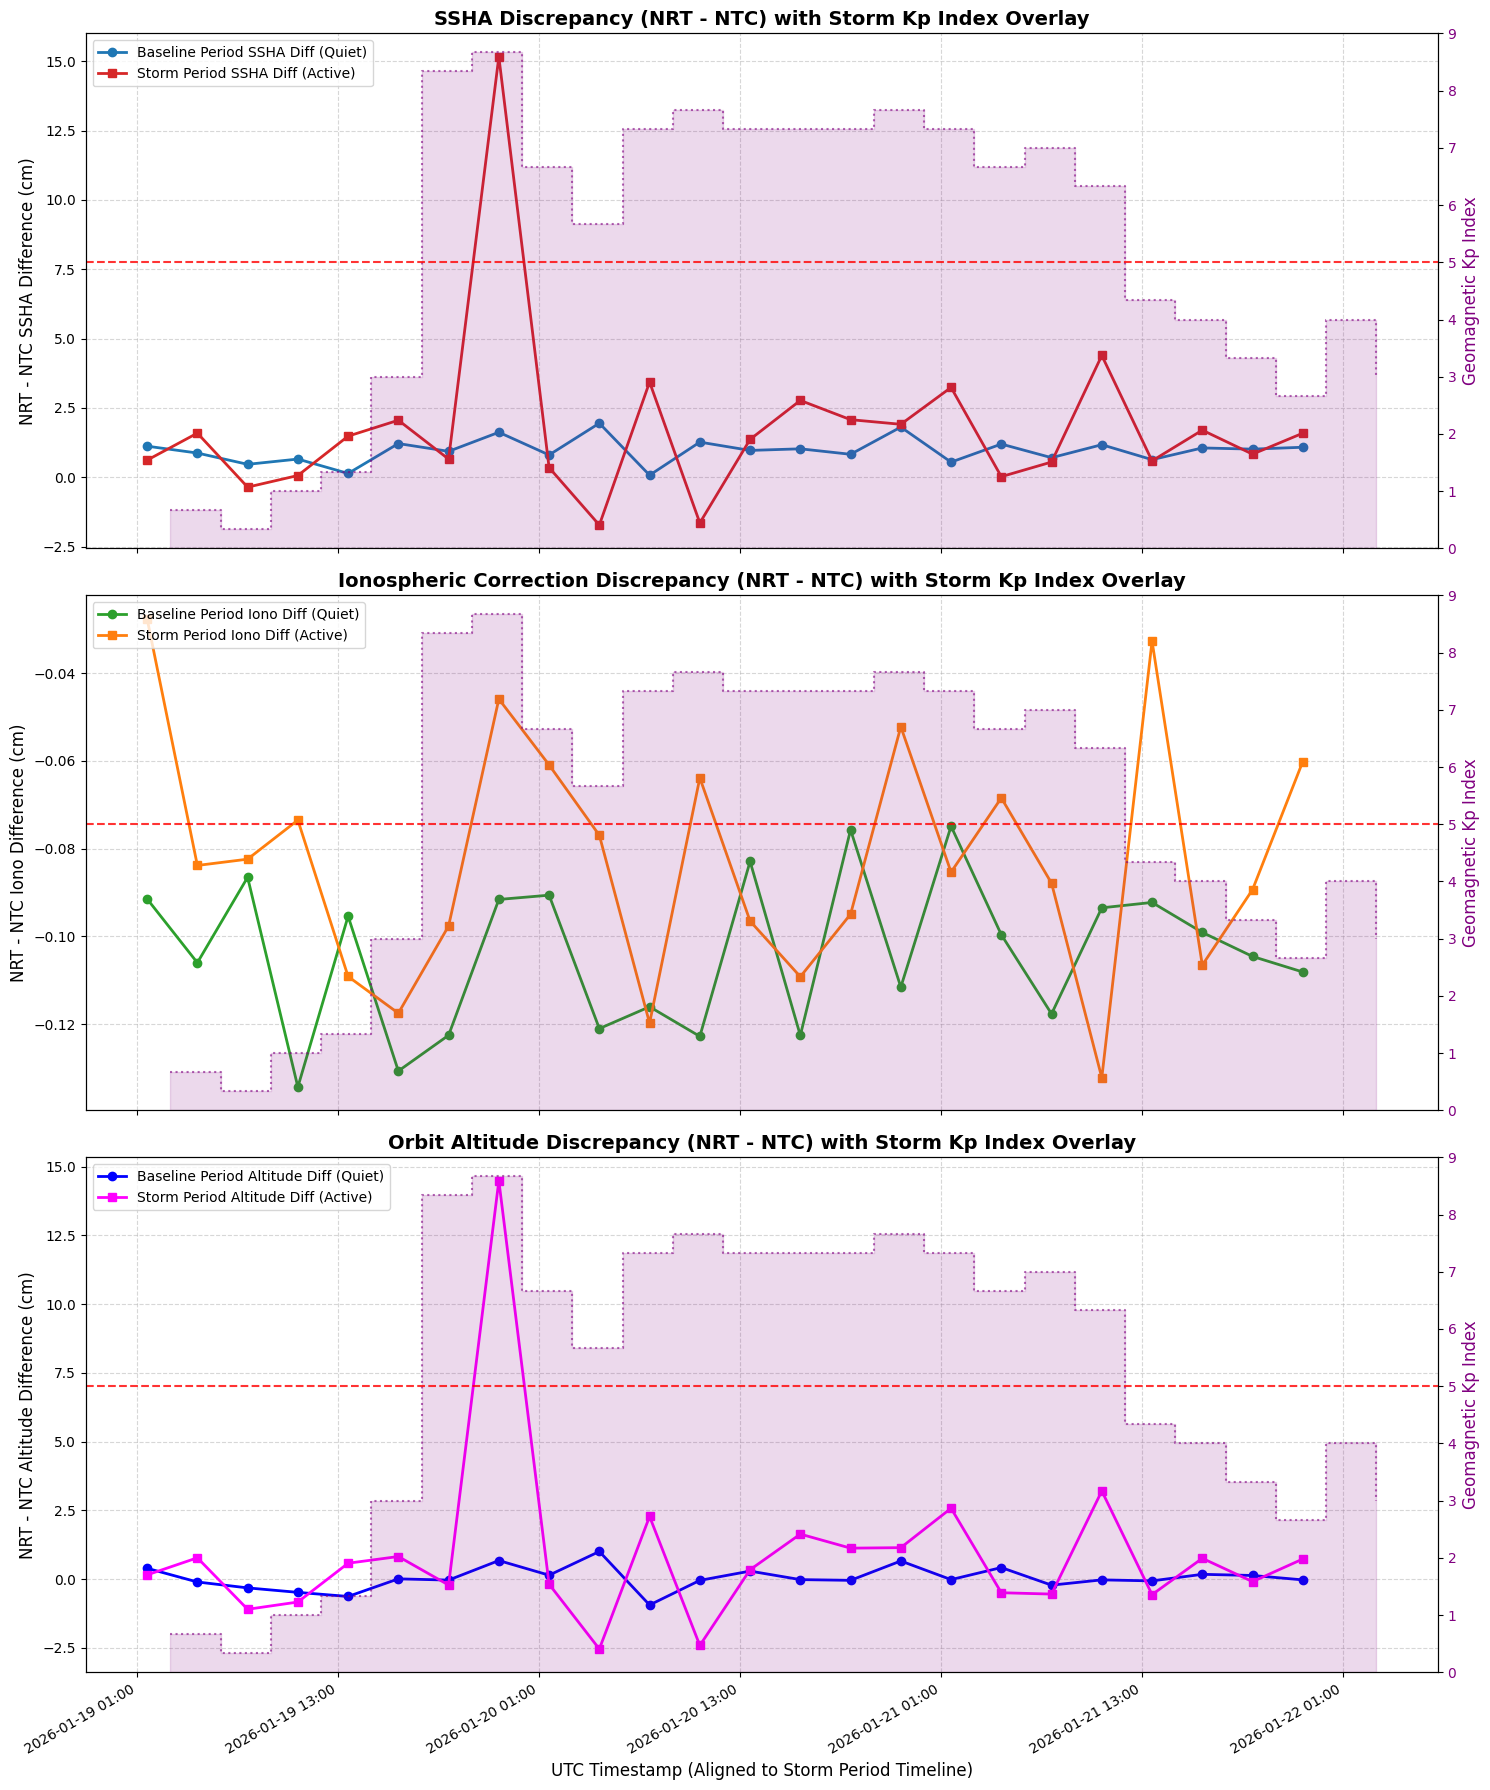

In [30]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.dates as mdates

# Clone data frames to avoid warnings
base_df = base_compare.copy()
storm_df = storm_compare.copy()

# 1. Sort values sequentially
base_df = base_df.sort_values('time_sec')
storm_df = storm_df.sort_values('time_sec')

base_start = base_df['time_sec'].min()
storm_start = storm_df['time_sec'].min()

# Calculate relative hours for binning process
base_df['hours_elapsed'] = (base_df['time_sec'] - base_start).dt.total_seconds() / 3600.0
storm_df['hours_elapsed'] = (storm_df['time_sec'] - storm_start).dt.total_seconds() / 3600.0

# 2. Resample/Bin data into 3-hour intervals
base_binned = base_df.groupby(pd.cut(base_df['hours_elapsed'], bins=np.arange(0, 75, 3))).mean(numeric_only=True)
storm_binned = storm_df.groupby(pd.cut(storm_df['hours_elapsed'], bins=np.arange(0, 75, 3))).mean(numeric_only=True)

# Map bin centers (hours) back to absolute datetimes relative to the start of each dataset
bin_hours = np.arange(1.5, 75, 3)[:len(base_binned)]
base_times = base_start + pd.to_timedelta(bin_hours, unit='h')
storm_times = storm_start + pd.to_timedelta(bin_hours, unit='h')

# 3. Align Kp timestamps directly (using real calendar UTC timestamps)
kp_temp = kp_df.copy().sort_values('Interval start (UTC)')
kp_temp = kp_temp[(kp_temp['Interval start (UTC)'] >= storm_start) & (kp_temp['Interval start (UTC)'] <= storm_start + pd.Timedelta(hours=75))]

# 4. Create Plots
fig, axes = plt.subplots(3, 1, figsize=(15, 18), sharex=True)

# --- SUBPLOT 1: SSHA Difference (NRT - NTC) vs Kp ---
axes[0].plot(storm_times, base_binned['d_ssha'] * 100, label='Baseline Period SSHA Diff (Quiet)', color='#1f77b4', marker='o', linewidth=2)
axes[0].plot(storm_times, storm_binned['d_ssha'] * 100, label='Storm Period SSHA Diff (Active)', color='#d62728', marker='s', linewidth=2)
axes[0].set_title('SSHA Discrepancy (NRT - NTC) with Storm Kp Index Overlay', fontsize=14, fontweight='bold')
axes[0].set_ylabel('NRT - NTC SSHA Difference (cm)', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(fontsize=10, loc='upper left')

# Secondary Y-Axis for Kp index
ax0_kp = axes[0].twinx()
ax0_kp.fill_between(kp_temp['Interval start (UTC)'], kp_temp['Kp'], color='purple', alpha=0.15, step='post', label='Geomagnetic Kp Index')
ax0_kp.plot(kp_temp['Interval start (UTC)'], kp_temp['Kp'], color='purple', linestyle=':', drawstyle='steps-post', alpha=0.6, linewidth=1.5)
# Add storm threshold line at Kp = 5
ax0_kp.axhline(5.0, color='red', linestyle='--', linewidth=1.5, alpha=0.8, label='Storm Threshold (Kp >= 5)')
ax0_kp.set_ylabel('Geomagnetic Kp Index', color='purple', fontsize=12)
ax0_kp.tick_params(axis='y', labelcolor='purple')
ax0_kp.set_ylim(0, 9)

# --- SUBPLOT 2: Ionospheric Correction Difference (NRT - NTC) vs Kp ---
axes[1].plot(storm_times, base_binned['d_iono'] * 100, label='Baseline Period Iono Diff (Quiet)', color='#2ca02c', marker='o', linewidth=2)
axes[1].plot(storm_times, storm_binned['d_iono'] * 100, label='Storm Period Iono Diff (Active)', color='#ff7f0e', marker='s', linewidth=2)
axes[1].set_title('Ionospheric Correction Discrepancy (NRT - NTC) with Storm Kp Index Overlay', fontsize=14, fontweight='bold')
axes[1].set_ylabel('NRT - NTC Iono Difference (cm)', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(fontsize=10, loc='upper left')

# Secondary Y-Axis for Kp index
ax1_kp = axes[1].twinx()
ax1_kp.fill_between(kp_temp['Interval start (UTC)'], kp_temp['Kp'], color='purple', alpha=0.15, step='post', label='Geomagnetic Kp Index')
ax1_kp.plot(kp_temp['Interval start (UTC)'], kp_temp['Kp'], color='purple', linestyle=':', drawstyle='steps-post', alpha=0.6, linewidth=1.5)
# Add storm threshold line at Kp = 5
ax1_kp.axhline(5.0, color='red', linestyle='--', linewidth=1.5, alpha=0.8, label='Storm Threshold (Kp >= 5)')
ax1_kp.set_ylabel('Geomagnetic Kp Index', color='purple', fontsize=12)
ax1_kp.tick_params(axis='y', labelcolor='purple')
ax1_kp.set_ylim(0, 9)

# --- SUBPLOT 3: Altitude Difference (NRT - NTC) vs Kp ---
axes[2].plot(storm_times, base_binned['d_alt'] * 100, label='Baseline Period Altitude Diff (Quiet)', color='blue', marker='o', linewidth=2)
axes[2].plot(storm_times, storm_binned['d_alt'] * 100, label='Storm Period Altitude Diff (Active)', color='magenta', marker='s', linewidth=2)
axes[2].set_title('Orbit Altitude Discrepancy (NRT - NTC) with Storm Kp Index Overlay', fontsize=14, fontweight='bold')
axes[2].set_xlabel('UTC Timestamp (Aligned to Storm Period Timeline)', fontsize=12)
axes[2].set_ylabel('NRT - NTC Altitude Difference (cm)', fontsize=12)
axes[2].grid(True, linestyle='--', alpha=0.5)
axes[2].legend(fontsize=10, loc='upper left')

# Secondary Y-Axis for Kp index
ax2_kp = axes[2].twinx()
ax2_kp.fill_between(kp_temp['Interval start (UTC)'], kp_temp['Kp'], color='purple', alpha=0.15, step='post', label='Geomagnetic Kp Index')
ax2_kp.plot(kp_temp['Interval start (UTC)'], kp_temp['Kp'], color='purple', linestyle=':', drawstyle='steps-post', alpha=0.6, linewidth=1.5)
# Add storm threshold line at Kp = 5
ax2_kp.axhline(5.0, color='red', linestyle='--', linewidth=1.5, alpha=0.8, label='Storm Threshold (Kp >= 5)')
ax2_kp.set_ylabel('Geomagnetic Kp Index', color='purple', fontsize=12)
ax2_kp.tick_params(axis='y', labelcolor='purple')
ax2_kp.set_ylim(0, 9)

# Format the dates on the shared x-axis nicely
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
axes[2].xaxis.set_major_locator(mdates.HourLocator(interval=12))
fig.autofmt_xdate() # Rotates labels to fit cleanly

plt.tight_layout()
plt.show()